# Olist E-Commerce — Sales and Customer Behaviour

**Business question:** Olist is a Brazilian marketplace connecting small sellers to large marketplaces. It has to decide which categories, sellers and regions to promote, where delivery and payment friction loses sales, and where review scores signal a fixable problem. Slow delivery and bad reviews lose repeat buyers; promoting the wrong categories wastes marketing spend; freight eats margin on low-value orders.

This notebook reproduces the headline charts from `notebooks/build_notebook.py`. All numbers come from the 9-file Kaggle Olist dataset (Sep 2016–Oct 2018) loaded into DuckDB; revenue is SUM(price) on delivered orders only.

In [ ]:
import duckdb
con = duckdb.connect('data/olist.duckdb', read_only=True)
print('tables:', [r[0] for r in con.execute('SHOW TABLES').fetchall()])

tables: ['categories', 'customers', 'geolocation', 'order_items', 'order_level', 'orders', 'payments', 'products', 'reviews', 'sellers']

In [ ]:
# row counts per table — the reviews file has 104,720 lines but
# 99,224 rows: review comments contain embedded newlines.
con.execute("SELECT 'orders' AS table_name, COUNT(*) FROM orders "
            "UNION ALL SELECT 'order_items', COUNT(*) FROM order_items "
            "UNION ALL SELECT 'products', COUNT(*) FROM products "
            "UNION ALL SELECT 'sellers', COUNT(*) FROM sellers "
            "UNION ALL SELECT 'customers', COUNT(*) FROM customers "
            "UNION ALL SELECT 'payments', COUNT(*) FROM payments "
            "UNION ALL SELECT 'reviews', COUNT(*) FROM reviews "
            "UNION ALL SELECT 'geolocation', COUNT(*) FROM geolocation "
            "UNION ALL SELECT 'categories', COUNT(*) FROM categories").fetchdf()

 table_name  count_star()
     orders         99441
order_items        112650
   products         32951
    sellers          3095
  customers         99441
   payments        103886
    reviews         99224
geolocation       1000163
 categories            71

In [ ]:
# headline KPIs — delivered orders only, revenue = SUM(price)
con.execute("SELECT COUNT(*) AS delivered_orders, "
            "ROUND(SUM(order_total), 2) AS revenue_brl, "
            "ROUND(AVG(order_total), 2) AS aov_brl, "
            "ROUND(MEDIAN(order_total), 2) AS median_order_value_brl, "
            "ROUND(SUM(freight_total), 2) AS freight_brl "
            "FROM order_level WHERE is_delivered").fetchdf()

 delivered_orders  revenue_brl  aov_brl  median_order_value_brl  freight_brl
            96478  13221498.11   137.04                   86.57   2198275.64

## 1. Growth: revenue grew ~9x in 2017, then plateaued

Delivered orders went from 750 in Jan 2017 (R$111,798) to 7,289 in Nov 2017 (R$987,765, the Black Friday peak), then settled around 6,100–7,000 orders a month in 2018. AOV barely moved (R$124–152 a month) — growth was volume, not bigger baskets. 2016 was a ramp: only 267 delivered orders in the whole year, and zero in Nov 2016.

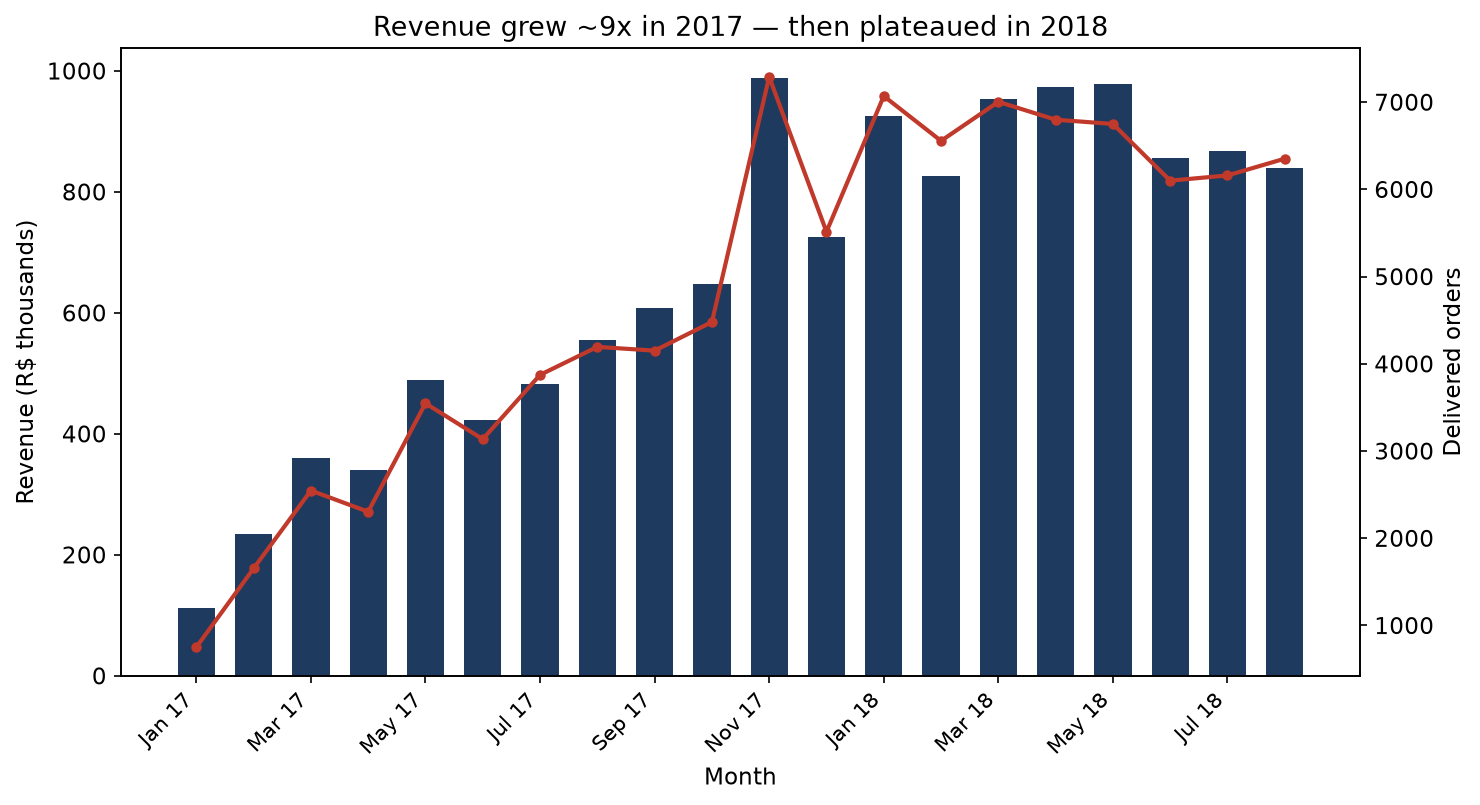

In [ ]:
# see notebooks/build_notebook.py — chart: monthly_revenue_orders
from IPython.display import Image
Image('images/monthly_revenue_orders.png')

## 2. Categories: broad, not winner-take-all

Health & beauty is the largest category (R$1,233,132, 9.33% of revenue), followed by watches & gifts (R$1,166,177, 8.82%) and bed, bath & table (R$1,023,435, 7.74%). The top 5 categories together are 39.83% of revenue and the top 10 are 62.43% — no single category to bet the marketplace on. The highest-ticket categories are musical instruments (R$301.66 per order) and small appliances (R$300.09); the lowest are electronics (R$61.60) and telephony (R$75.70).

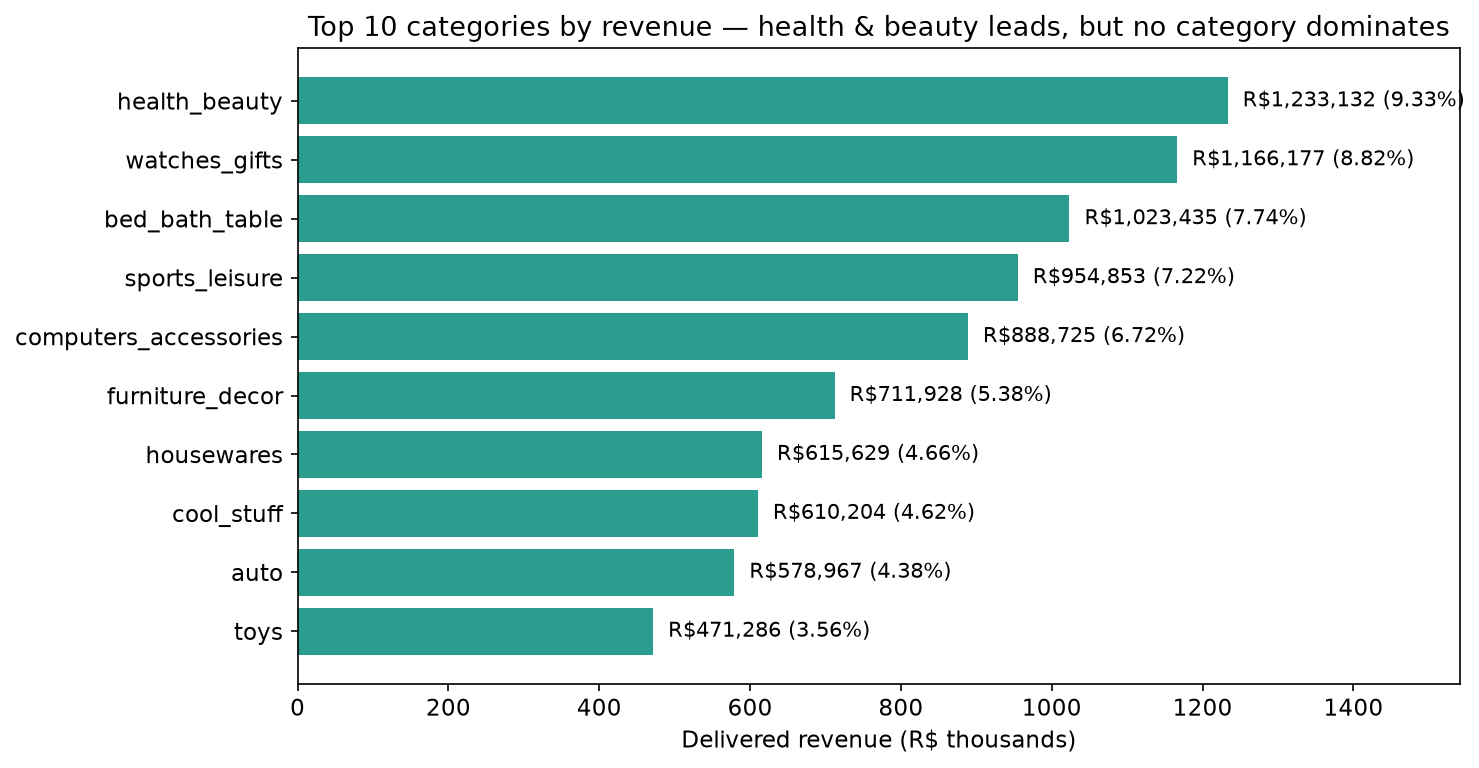

In [ ]:
Image('images/revenue_top10_categories.png')

## 3. Payments: credit card dominates, and installments track basket size

Credit card is used on 76.94% of orders (78.34% of payment value); boleto 19.90%, voucher 3.89%, debit card 1.54%. Credit-card AOV is R$142.95 vs R$121.40 for boleto and R$85.91 for voucher. Installments rise steeply with basket size: paid-in-full orders average R$82.27, 7–12 installments average R$299.57 — installments are how Brazilians afford big baskets, not a discount channel.

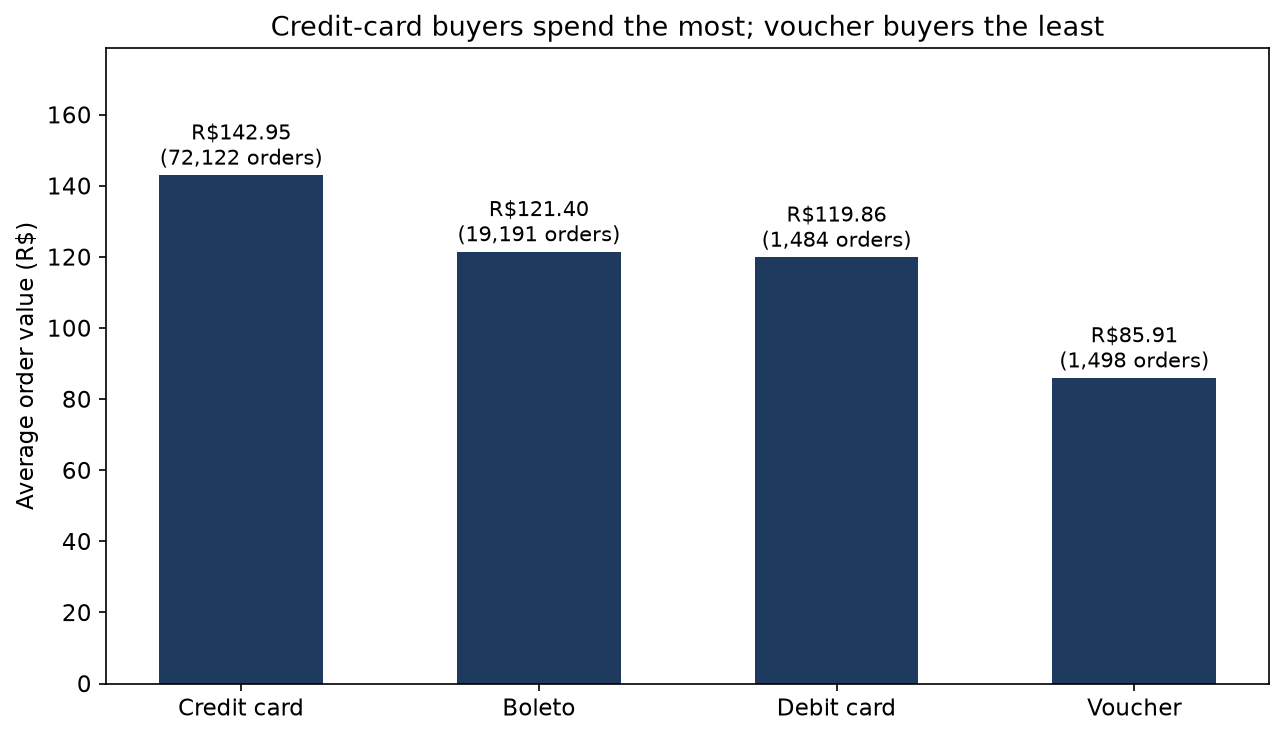

In [ ]:
Image('images/aov_by_payment_type.png')

## 4. Delivery: on time on average, but the North-East waits — and pays

Overall 93.23% of delivered orders arrive on time or early, median 10 days, mean 12.5 days. But the late rate is 17.43% in Maranhão (21.5 days average) and 13.76% in Ceará vs 4.49% in São Paulo (8.7 days). Freight is the quieter problem: R$2,198,276 in total, 16.63% of revenue, and on orders under R$50 freight averages 56.98% of the order value — 44.96% of those orders pay freight worth half the order or more.

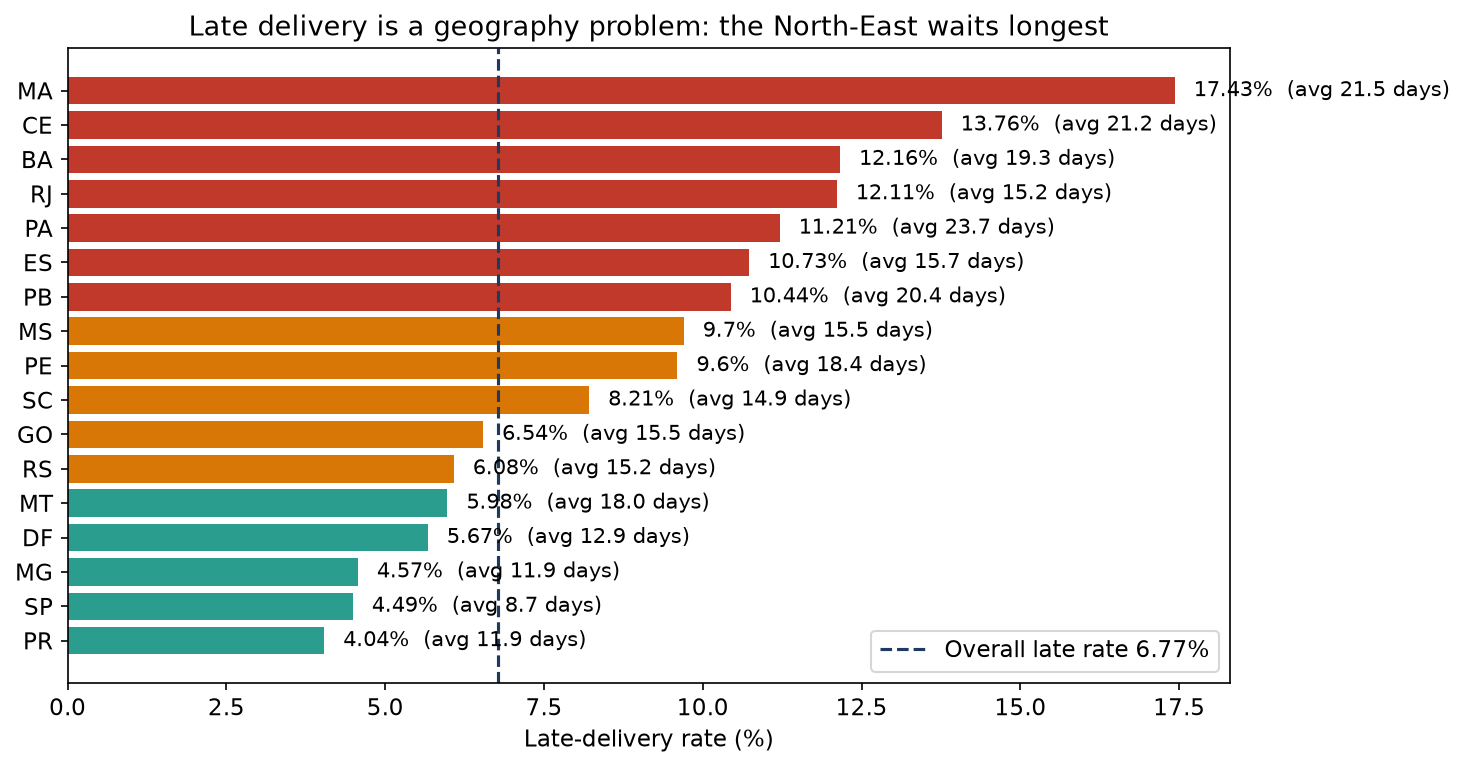

In [ ]:
Image('images/late_delivery_rate_by_state.png')

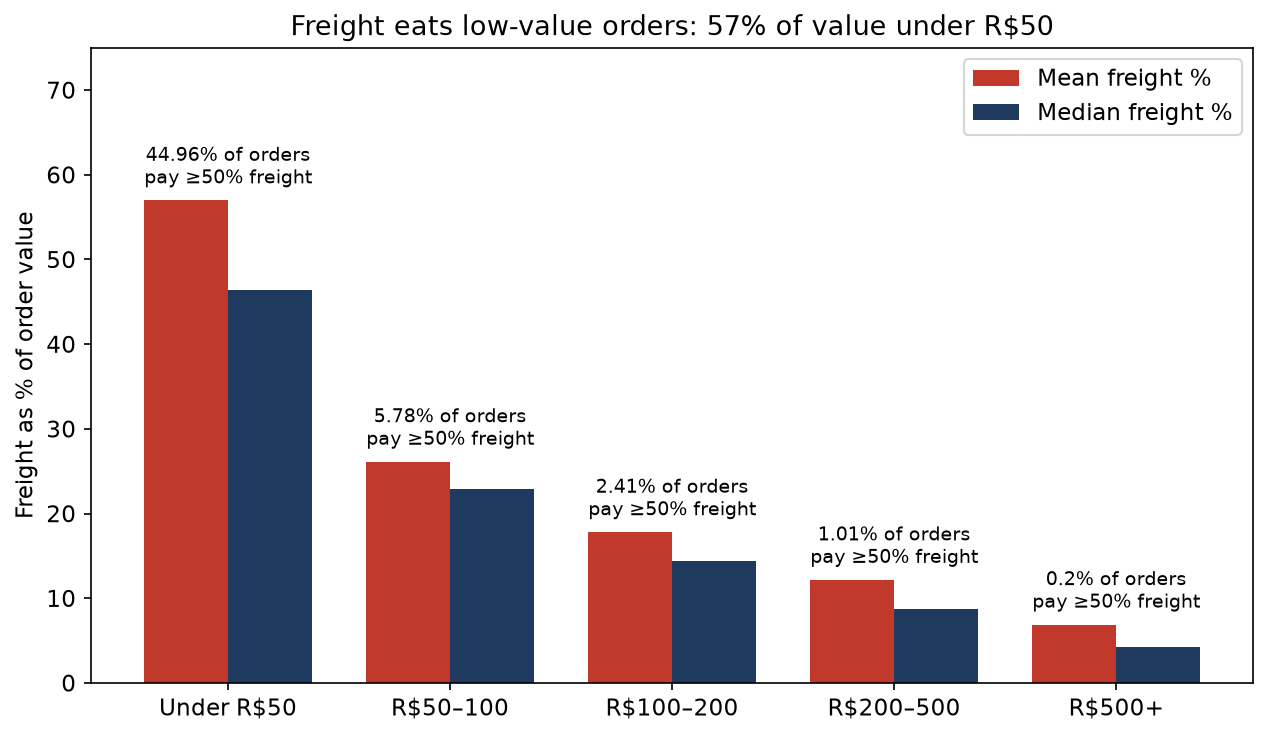

In [ ]:
Image('images/freight_pct_by_price_band.png')

## 5. Reviews: late delivery is the review killer

The average review is 4.09 stars (57.78% are 5-star, 11.51% are 1-star). Split by delivery timing the gap is stark: on-time orders average 4.29, late orders 2.27 — and 53.69% of late orders get 1 star vs 6.58% of on-time orders. The damage scales with the delay: 1–3 days late averages 3.29, 4–7 days 2.11, 8+ days 1.70 (79.18% score 1–2). Category barely matters for lateness (4.3–8.1% late across categories) — this is a logistics problem, not a product problem. The worst-reviewed category is office furniture (3.51), which also has the longest average delivery time (20.8 days).

In [ ]:
# one score per order, then averaged by timing — no order counted twice
con.execute("SELECT timing, COUNT(*) AS orders_with_review, "
            "ROUND(AVG(order_review_score), 3) AS avg_review_score "
            "FROM (SELECT CASE WHEN ol.late_days > 0 THEN 'late' "
            "ELSE 'on time / early' END AS timing, rpo.order_review_score "
            "FROM order_level ol JOIN (SELECT order_id, "
            "AVG(review_score) AS order_review_score FROM reviews "
            "GROUP BY order_id) rpo ON ol.order_id = rpo.order_id "
            "WHERE ol.is_delivered AND ol.late_days IS NOT NULL) "
            "GROUP BY timing ORDER BY timing").fetchdf()

         timing  orders_with_review  avg_review_score
           late                6381             2.272
on time / early               89443             4.291

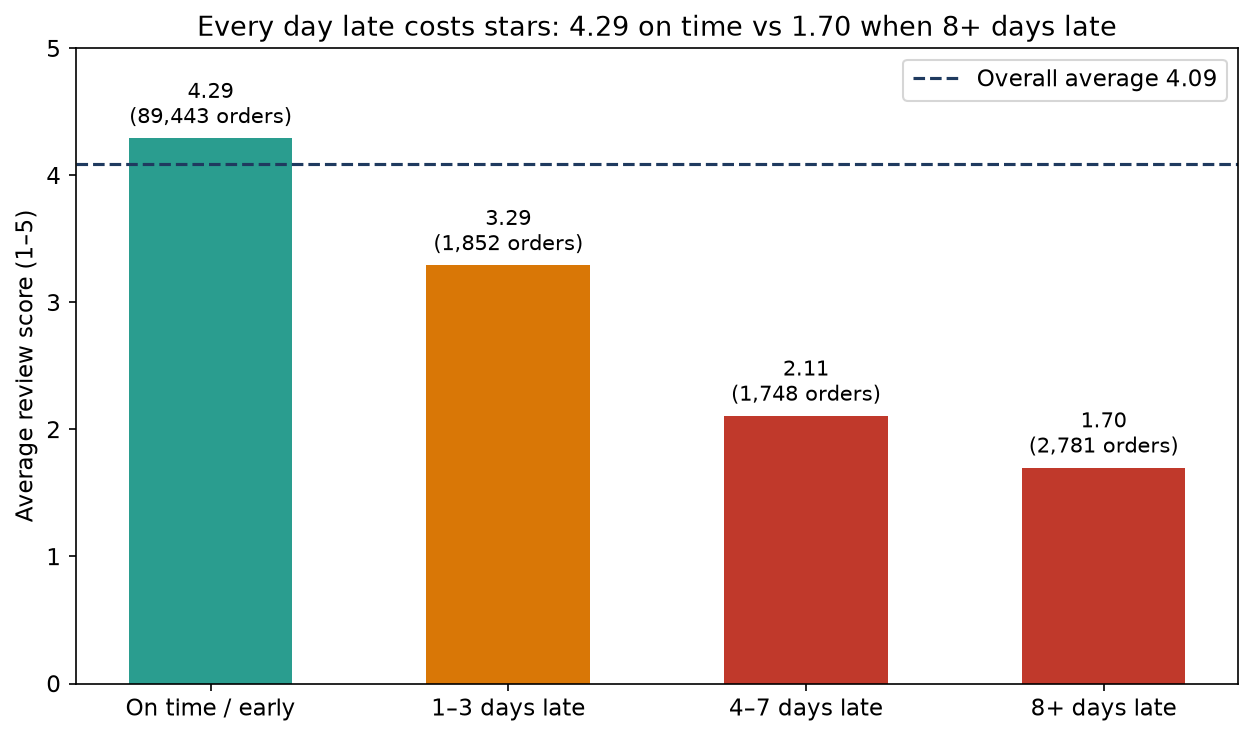

In [ ]:
Image('images/review_score_by_lateness.png')

## 6. Customers and sellers: almost everyone is a first-time buyer

96.88% of the 96,096 unique customers ordered exactly once; only 2,997 (3.12%) ordered twice or more, and repeat buyers contribute just 5.75% of revenue — and spend less per order (R$124.67 vs R$137.88). Sellers are equally spread out: 2,970 sellers share the revenue, the top 10 take 13.27% and the top 100 take 45.52%; the median seller earned R$846.17 over the whole period. São Paulo sellers supply 64.36% of item value while São Paulo buyers are 38.33% of revenue — the marketplace ships out of SP to the rest of Brazil, which is exactly why freight and delivery times bite outside the South-East.